In [3]:
import os
import sys

current_path = os.path.abspath(os.getcwd())
base_path = os.path.abspath(os.path.join(current_path, '../../../../'))
sys.path.append(base_path)

import numpy as np
import matplotlib.pyplot as plt  
import pandas as pd
from IPython.display import display


import project_images_loader as pil
from tqdm import tqdm

import utils.util as util
import utils.functions as fc
import utils.nifti_functions as nfc
import utils.visualization as vis

import test_code.dfield_approach_elastix.constants as cts
import seaborn as sns

from sklearn.preprocessing import StandardScaler, MinMaxScaler
from sklearn.decomposition import PCA

from scipy import stats

from features_loader import FeaturesLoader

np.set_printoptions(precision=4)


# Load data

In [7]:
satistics_results = f'{current_path}/features'
name = 'HAA_HUNT_summary_MRI_DTI_ok_HL'
reader = FeaturesLoader(satistics_results, name)

matching_ids = pil.get_matching_ids()
data = reader.get_df("SubjID", matching_ids)
data = data.sort_values(by='SubjID')
# data_columns = data.columns.tolist()
display(data.shape)
display(data.head())

print(f"nuber of unique ages: {data['Age'].nunique()}")
print(np.unique(data['Age'].values, return_counts=True))
print(np.unique(data['Sex'].values, return_counts=True))

(687, 256)

,SubjID,VisitID,VisitNumber,StudyDate,MMPS_version,MMIL_Processing_Date,Sex,Age,Group,Site,...,CortContrastWhitectxrhcaudalmiddlefrontal,CortContrastWhitectxrhcorpuscallosum,CortContrastWhitectxrhcuneus,CortContrastWhitectxrhentorhinal,CortContrastWhitectxrhfusiform,CortContrastWhitectxrhinferiorparietal,CortContrastWhitectxrhinferiortemporal,CortContrastWhitectxrhisthmuscingulate,CortContrastWhitectxrhlateraloccipital,CortContrastWhitectxrhlateralorbitofrontal
8,9410000000039,9410000000039,1,19000101,225,26-Oct-2011,F,51,,HUNT,...,93.4901,121.1888,89.5995,94.7505,95.9306,96.3060,92.3841,104.4059,87.8722,91.7198
769,9410000000046,9410000000046,1,19000101,225,26-Oct-2011,M,63,,HUNT,...,89.5530,109.2180,83.6935,79.7070,86.0511,90.8724,83.0841,94.1982,83.4201,88.5160
544,9410000000053,9410000000053,1,19000101,225,26-Oct-2011,M,60,,HUNT,...,77.8755,88.3218,74.5077,64.4854,74.4769,80.1154,73.7721,78.2536,76.6607,74.8588
147,9410000000077,9410000000077,1,19000101,225,26-Oct-2011,F,54,,HUNT,...,84.5621,105.7476,84.1750,80.2314,88.0558,91.0058,86.0854,94.0066,85.1286,85.6214
289,9410000000091,9410000000091,1,19000101,225,26-Oct-2011,M,56,,HUNT,...,77.2036,96.4338,76.6101,70.9890,78.0744,83.2062,76.2892,83.7759,77.8517,77.4974


nuber of unique ages: 17
(array([50, 51, 52, 53, 54, 55, 56, 57, 58, 59, 60, 61, 62, 63, 64, 65, 66],
      dtype=int64), array([ 8, 24, 44, 36, 43, 56, 49, 44, 43, 51, 55, 47, 53, 45, 44, 37,  8],
      dtype=int64))
(array(['F', 'M'], dtype=object), array([372, 315], dtype=int64))


,bpf_hunt3,bpf_hunt4,bpf_dif,bpf_div
0,0.752932,0.733999,0.018933,0.974854
1,0.730270,0.689742,0.040529,0.944502
2,0.734714,0.692709,0.042005,0.942829
3,0.777995,0.743035,0.034961,0.955063
4,0.756191,0.715147,0.041044,0.945722


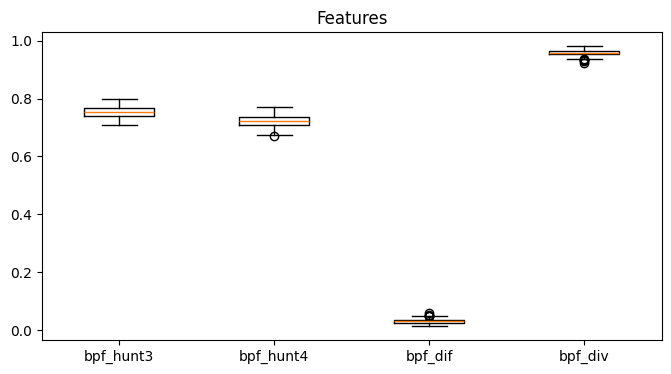

In [2]:
satistics_results = f'{current_path}/features/whole_brains_stats'
columns = None

reader = FeaturesLoader(satistics_results)
data = reader.get_df(columns=columns,
                     remove_columns=False, 
                     return_patient_id=True, 
                     remove_patients=pil.EXCLUDED_PATIENTS)

data_ids = data.pop('patient_id').tolist()
data_columns = data.columns.tolist()
display(data.head())

vis.plot_data_voxplot(data, data_columns, figsize=(8,4))


# Preprocessing

### Remove outlayers

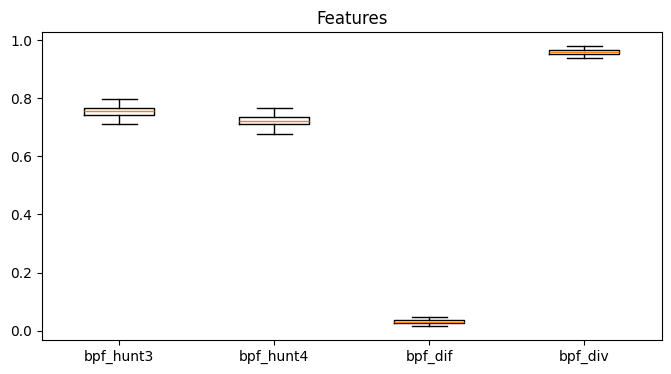

In [3]:
def remove_outliers_zscore(data, threshold=3):
    z_scores = stats.zscore(data)
    abs_z_scores = np.abs(z_scores)
    filtered_data = data[(abs_z_scores < threshold).all(axis=1)]
    return filtered_data

data_no_outlayers = remove_outliers_zscore(data, threshold=2.5)
vis.plot_data_voxplot(data_no_outlayers, data_columns, figsize=(8,4))

### Standarize and normalize

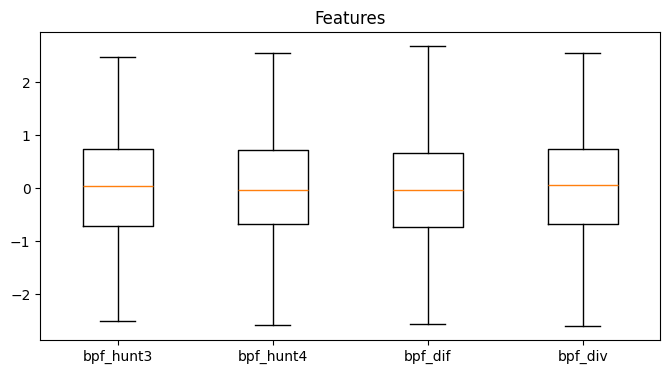

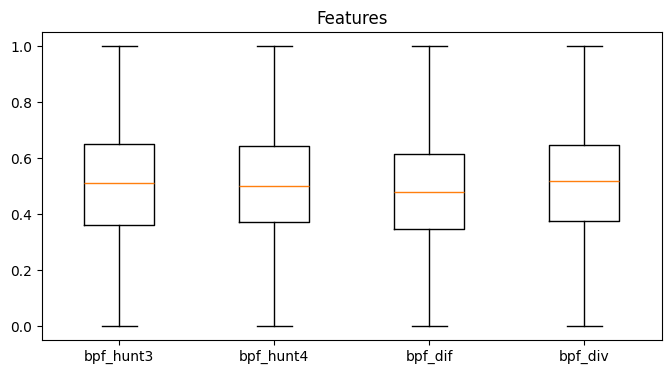

In [4]:
# Standardize each column
scaler = StandardScaler()
data_standardized = scaler.fit_transform(data_no_outlayers)
data_standardized_df = pd.DataFrame(data_standardized, columns=data_columns)

# Normalize each column
normalizer = MinMaxScaler()
data_normalized = normalizer.fit_transform(data_standardized)
data_normalized_df = pd.DataFrame(data_normalized, columns=data_columns)


vis.plot_data_voxplot(data_standardized, data_columns, figsize=(8,4))
vis.plot_data_voxplot(data_normalized_df, data_columns, figsize=(8,4))


### Correlation

High correlated: ['bpf_hunt3', 'bpf_dif']


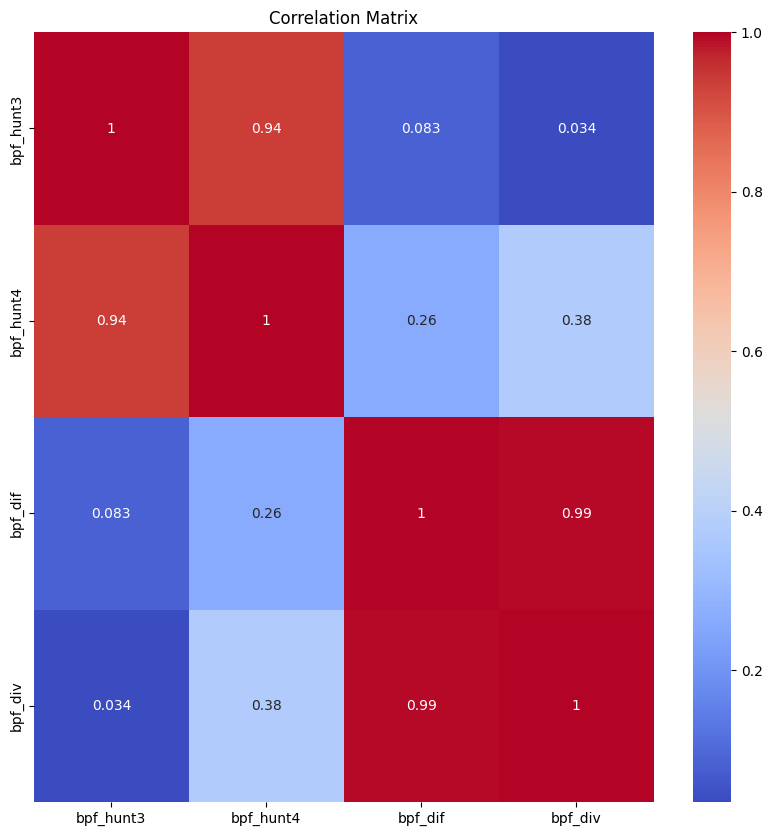

In [5]:
corr_th = 0.9

corr_df = data_normalized_df.corr().abs()
mask = np.triu(np.ones_like(corr_df, dtype=bool))
tri_df = corr_df.mask(mask)
to_drop = [c for c in tri_df.columns if any(tri_df[c] > corr_th)]

print(f"High correlated: {to_drop}")
vis.plot_data_precomputed_correlation_df(corr_df, data_normalized_df, figsize=(10, 10))



### Visualize individual features

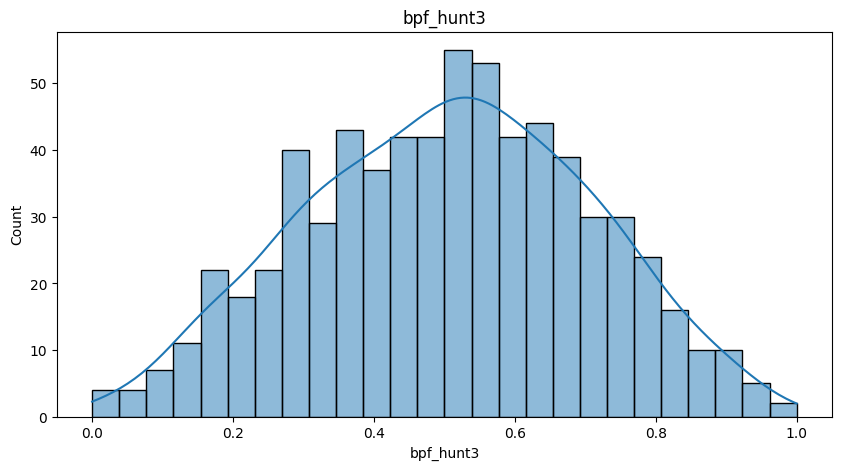

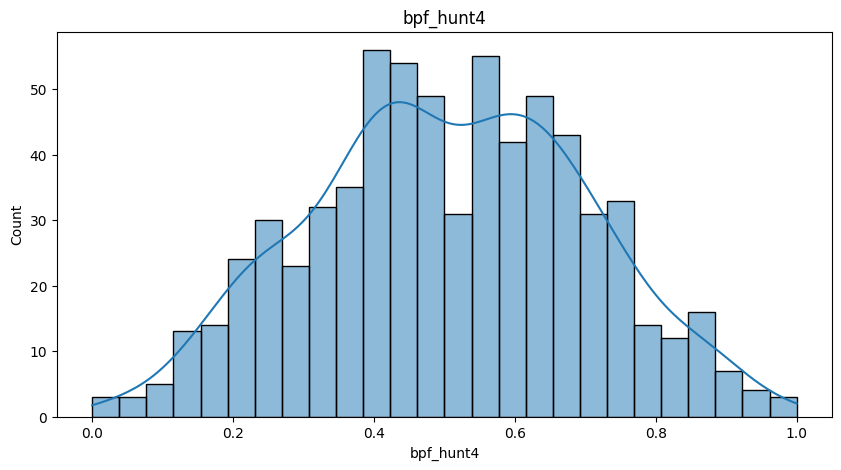

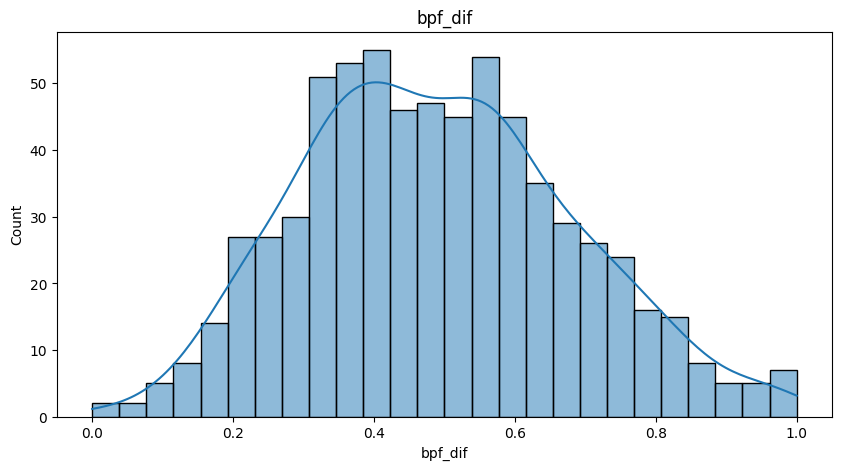

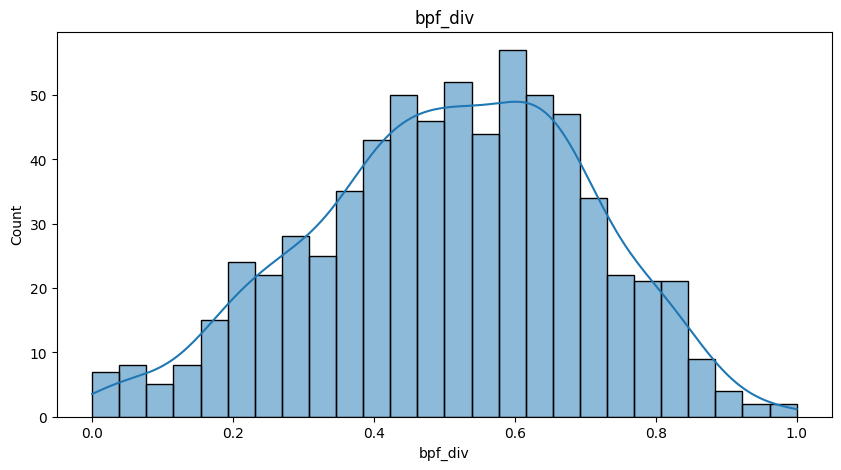

In [6]:
bins = int(np.sqrt(data_normalized.shape[0]))
# bins="auto"
binrange = (0.0,1.0)
data_to_hist_df = data_normalized_df

vis.plot_hist_all_data_df(data_to_hist_df, bins=bins, binrange=binrange, figsize=(10, 5))

### Visualize 2D

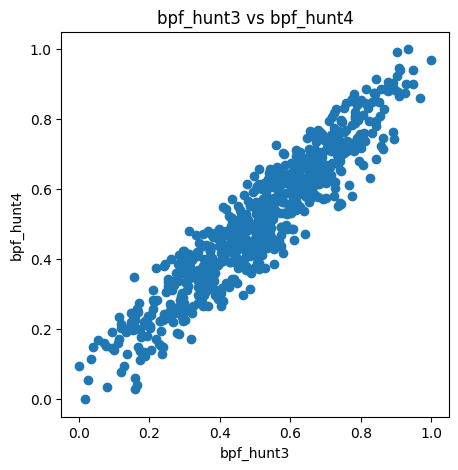

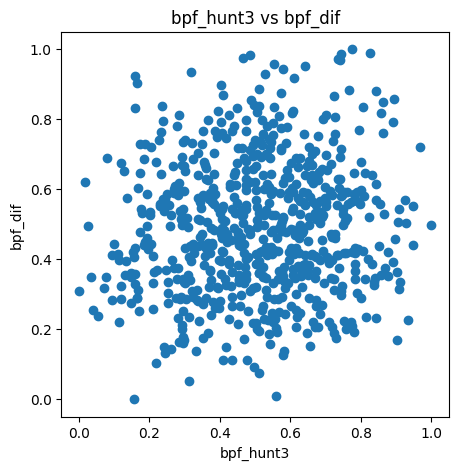

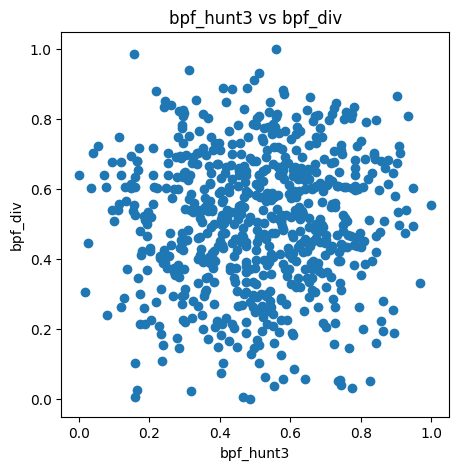

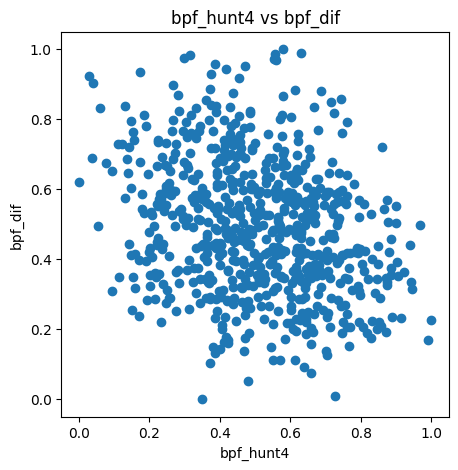

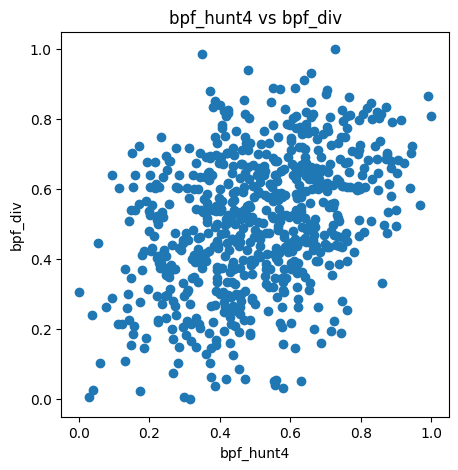

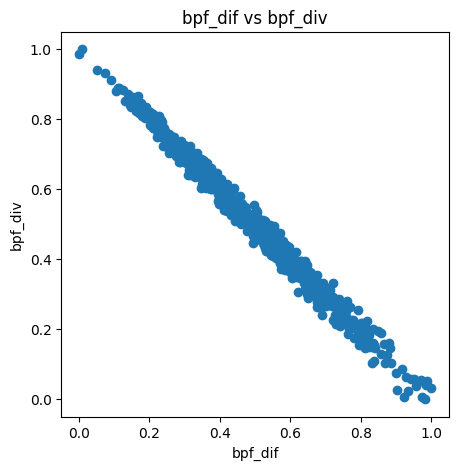

In [8]:
vis.plot_2D_points_2v2_all_data_df(data_to_hist_df, figsize=(5, 5))

### PCA

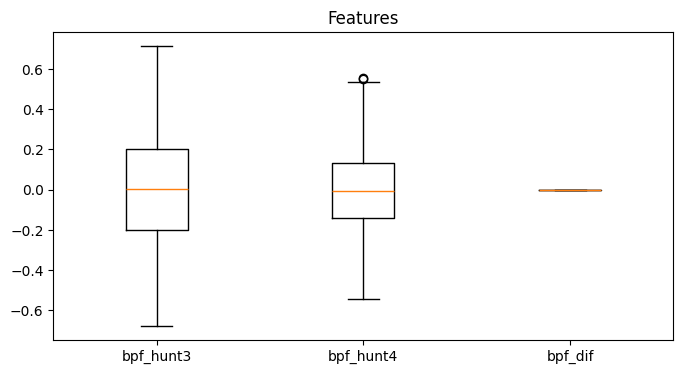

In [9]:
pca_obj = PCA(n_components=len(data_columns)-1)
data_pca = pca_obj.fit_transform(data_normalized[:,:3])

vis.plot_data_voxplot(data_pca, data_columns[:3], figsize=(8,4))



# Clustering

In [ ]:
nb_clusters = 16
random_state = 42

def count_not_matching_clusters(clusters1, clusters2):
    count = 0
    for i in range(len(clusters1)):
        if clusters1[i] != clusters2[i]:
            count += 1
    return count

## K-means

In [ ]:
from sklearn.cluster import KMeans

kmeans = KMeans(n_clusters=nb_clusters, random_state=random_state)
clusters_kmeans = kmeans.fit_predict(data_pca)
# print(clusters_kmeans)
print(np.unique(np.array(clusters_kmeans), return_counts=True)[1])

# [34 10 33 19 19 26 28 19 29  3  5 21 24  9  9 15]
# [38 19 46 40  1 11  7 20 16 24 27 11 35  3  1  4]

[34 10 33 19 19 26 28 19 29  3  5 21 24  9  9 15]


## EM

In [ ]:
from sklearn.mixture import GaussianMixture

# Crear el objeto GaussianMixture
gmm = GaussianMixture(n_components=nb_clusters, random_state=random_state, init_params='kmeans', max_iter=10000, tol=1e-6)
clusters_em = gmm.fit_predict(data_pca)
print(np.unique(np.array(clusters_em), return_counts=True)[1])

count_not_matching_clusters(clusters_kmeans, clusters_em)


[35 10 33 19 19 25 28 19 29  3  5 21 24  9  9 15]


1

## Mean-shift

In [ ]:
from sklearn.cluster import MeanShift


clustering = MeanShift()
clustering.fit(data_pca)

# Obtener las etiquetas de los clusters y los centros de los clusters
clusters_meanshift = clustering.labels_
print(len(np.unique(clusters_meanshift)))
print(np.unique(np.array(clusters_meanshift), return_counts=True)[1])
# cluster_centers = clustering.cluster_centers_
# print(clusters_meanshift)


7
[293   4   2   1   1   1   1]


## DBSCAN

In [ ]:
from sklearn.cluster import DBSCAN

dbscan = DBSCAN(eps=7, min_samples=2)
dbscan.fit(data_pca)
clusters_dbscan = dbscan.labels_

print(len(np.unique(clusters_dbscan)))
print(np.unique(np.array(clusters_dbscan), return_counts=True)[1])

# print(clusters_dbscan)

1
[303]


# Clustering visualization

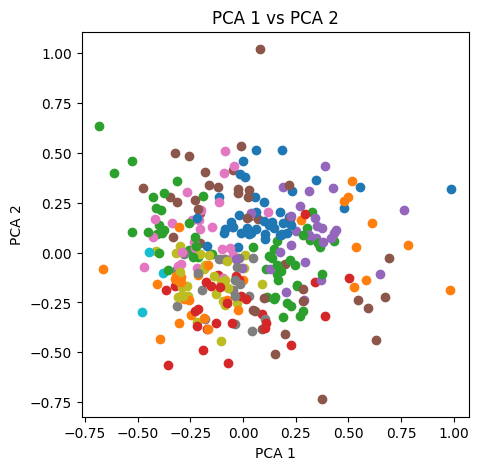

In [ ]:
# import matplotlib.pyplot as plt


# # Obtener las coordenadas de los componentes principales
# x = data_pca[:, 0]
# y = data_pca[:, 1]

# # Crear una figura y un conjunto de ejes
# fig, ax = plt.subplots()

# # Iterar sobre los elementos y asignar un color diferente a cada cluster
# for i, cluster in enumerate(clusters_kmeans):
#     # Obtener el color correspondiente al cluster
#     color = 'C{}'.format(cluster)
    
#     # Plotear el punto con el color correspondiente
#     ax.scatter(x[i], y[i], color=color)

# # Mostrar el gráfico
# plt.show()

cluster = clusters_em

plot_points(data_pca[:, 0], data_pca[:, 1], 'PCA 1', 'PCA 2', cluster, figsize=(5, 5))
# plot_points(data_normalized[:, 0], data_normalized[:, 1], 'PCA 1', 'PCA 2', cluster, figsize=(5, 5))
# plot_points(data_standardized[:, 0], data_standardized[:, 1], 'PCA 1', 'PCA 2', cluster, figsize=(5, 5))
# plot_points(data.values[:, 0], data.values[:, 1], 'PCA 1', 'PCA 2', cluster, figsize=(5, 5))

# Save clustering

In [ ]:
data_ids
clusters_em

df = pd.DataFrame({'patient_id': data_ids, 'cluster_em': clusters_em, 'cluster_kmeans': clusters_kmeans, 'cluster_meanshift': clusters_meanshift, 'cluster_dbscan': clusters_dbscan})
df = df.astype(int)

df_name = f'C{nb_clusters}_T{nb_tissues}_{"-".join(metrics_name)}.csv'
# df.to_csv(f'{current_path}/clusters/{df_name}', index=False)